## 07B Advanced Model for Lapse: Random Forest

#### Purpose
- Build a **random forest** for lapse (`LAPSE`: a cancellation during the term or a non-renewal at its end) and check whether it identifies lapses **better than the logistic regression baseline (06b)** and a simple business rule.
- LightGBM and XGBoost are built in a separate notebook (Justin). All three use the same features, split and measures, so notebook 08 can compare them fairly.

#### What a random forest is, in plain words
A **decision tree** asks a chain of yes/no questions ("Is the policy in its first year?", "Is it in flood zone X?") and ends in a group of similar policy-years; the share of lapses in that group is the tree's probability.
A single tree is unstable, so a **random forest** grows hundreds of trees, each on a random part of the rows and allowed to look at a random handful of features at each question, and **averages** their answers.
Unlike logistic regression, trees find **combinations** (for example "new business *and* not mortgage-required") and **bends and thresholds** (lapse drops sharply in the first years, then flattens) on their own.

#### How we judge the model (same as 06b)
The forest gives every policy-year a **lapse probability**. To act on it, the retention team flags the riskiest policy-years, which turns the probability into a **yes/no prediction**. We judge those predictions with the measures from our course:

| Measure | Question it answers |
|---|---|
| **Confusion matrix** | How many lapses did we flag (TP), miss (FN), and how many stayers did we flag by mistake (FP)? |
| **Accuracy** | Share of all predictions that are right. Misleading here: with 12% lapses, "nobody lapses" is 88% accurate |
| **Precision** | Of the policies we flag, how many really lapse? (how well the retention budget is spent) |
| **Recall** | Of all lapses, how many did we flag? (how much of the problem we reach) |
| **F1** | One number balancing precision and recall |
| **ROC curve and AUC** | How well the model **ranks** policies over every possible cut-off (0.5 = random, 1.0 = perfect) |

A yes/no prediction needs a **cut-off**. As in 06b we flag the **riskiest 10%, 20% and 30%** of policy-years, with the cut-off taken from the *training* years, and show the default 0.5 for comparison.

The probability measures (log loss, Brier score, calibration) are kept in an **ad hoc section** (Section 9) for reference.

#### Models in this notebook
| Model | What it is |
|---|---|
| RF 1: starting settings | A sensible first forest, not tuned |
| RF 2: tuned | Settings chosen with the same time-based folds as 06b: **the model carried forward** |

#### Data size
The training split has 26.8M policy-years, far too many for a random forest on a laptop. We train on a **random sample of 1M training rows** (seed 42, the same rows every run) and score **every** test row (7.1M, 2021–2022), so the results are comparable with 06b.

#### Steps:
1. Load the features and the training sample
2. Naive benchmarks (same as 06b)
3. Preprocessing for trees
4. RF 1: starting settings
5. RF 2: tune with time-based folds, then train
6. Score the test years (2021–2022)
7. Results: confusion matrices, accuracy, precision, recall, F1, ROC-AUC; lapses captured by decile; leak check; premium at risk (draft)
8. What drives the forest (feature importance)
9. Ad hoc: probability measures (log loss, Brier score, calibration)
10. Save the model and results

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-16
- **Date Modified:** 2026-11-17 (v3: course classification measures first; probability measures in an ad hoc section)

### Section 0. Load the libraries and working directory
Same setup as 06b, so the notebook runs on every teammate's machine.

**Before running:** the file `data/processed/features.parquet` (made by notebook 05) must be in your `data/processed/` folder. It is not on GitHub (data files never are); get it from Sebastian.

#### 0.1 Imports, paths and random seed

In [38]:
# Reload our own src/ files automatically if a teammate changes them (2 = reload everything before each cell)
%load_ext autoreload
%autoreload 2

import sys                                    # lets us tell Python where our src/ folder is
from pathlib import Path                      # works with folder and file paths on any computer
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())   # walk up from this folder to the repo root (the folder that holds src/)
sys.path.insert(0, str(ROOT))                 # put the repo root first on Python's search list, so "from src..." works

import time                                   # to time the slow steps
import numpy as np                            # fast maths on arrays of numbers
import pandas as pd                           # tables (DataFrames)
import matplotlib.pyplot as plt               # charts

from sklearn.compose import ColumnTransformer         # applies a different preparation to different groups of columns
from sklearn.impute import SimpleImputer              # fills in missing values
from sklearn.pipeline import make_pipeline            # chains preparation steps into one object
from sklearn.preprocessing import OrdinalEncoder      # turns text categories into numbers (0, 1, 2, ...) for the trees
from sklearn.ensemble import RandomForestClassifier   # the random forest model
from sklearn.isotonic import IsotonicRegression       # the calibration step (Section 6)
from sklearn.metrics import brier_score_loss, log_loss   # the two scores we judge the model on

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs   # the team's standard folder locations
from src.db import connect, scalar                    # DuckDB connection and a helper that returns one number from a query
from src.features import apply_fixed_rules            # the fixed clean-up rules from notebook 05 (same as 06b)
from src.modeling import RandomSampleImputer          # fills chosen features with random training values (Section 3)

pd.options.display.float_format = "{:,.4g}".format    # show 4 significant digits, so small rates stay readable
ensure_dirs()                                         # create the output folders if they don't exist yet

FEATURES_FILE = PROCESSED / "features.parquet"        # the feature table made by notebook 05
assert FEATURES_FILE.exists(), f"Missing {FEATURES_FILE}: get features.parquet from Sebastian and put it in data/processed/"
print(f"repo: {ROOT}\nfeatures file: {FEATURES_FILE.name} ({FEATURES_FILE.stat().st_size / 1e9:.1f} GB)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
repo: /Users/loiscelorico/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk
features file: features.parquet (3.5 GB)


### Section 1. Load the features and the training sample

#### 1.1 Settings and the row loader
Exactly the same features, target and loader as 06b, so the models differ only in the algorithm.

| Setting | Value | Why |
|---|---|---|
| `TRAIN_ROWS` | 1,000,000 | Random training rows (2014–2020) for the final forests; fits in a laptop's memory |
| `TUNE_ROWS` | 500,000 | Random training rows for tuning (Section 5); tuning fits 24 forests, so it uses fewer rows |
| `N_CHUNKS` | 28 | The 7.1M test rows are scored in 28 pieces, so they never sit in memory at once |

In [39]:
# Step 1.1 Settings and the row loader (same as 06b)
SEED = 42                      # the team's random seed: same samples and same forests on every run
TARGET = "LAPSE"               # 1 = cancelled during the term or not renewed at its end; 0 = renewed
ID_COLS = ["period_id", "period_year"]   # row id and policy year: kept to trace rows, never used as features
TRAIN_ROWS = 1_000_000         # training sample for the final forests
TUNE_ROWS = 500_000            # training sample for tuning
N_CHUNKS = 28                  # number of pieces the test split is scored in

# The features we use, their kind and their missing-value plan, from notebook 05
plan = pd.read_csv(DOCS / "feature_plan.csv")          # one row per candidate feature, with the team's decisions
plan = plan[plan["use"]]                               # keep only the features marked "use" (leaky or empty ones are dropped)
FEATS = plan["feature"].tolist()                       # all feature names
NUMS = plan.loc[plan["kind"] == "num", "feature"].tolist()     # number features (premium, building age, ...)
CATS = plan.loc[plan["kind"] == "cat", "feature"].tolist()     # category features (flood zone, floors, ...)
FLAGS = plan.loc[plan["kind"] == "flag", "feature"].tolist()   # yes/no features (mandatory purchase, ...)
print(f"{len(FEATS)} features: {len(NUMS)} numbers, {len(CATS)} categories, {len(FLAGS)} flags")

con = connect(db_path=None, memory_limit="4GB")        # DuckDB in memory, allowed 4 GB (leaves room for the forest)
con.execute(f'''CREATE OR REPLACE VIEW lapse_pop AS
                SELECT * FROM read_parquet('{FEATURES_FILE}') WHERE in_pop_lapse''')   # a "view": the lapse population, read straight from the file

def prepare(df):
    '''Fixed clean-up rules (notebook 05) and compact types; returns X (features), y (target), ids.'''
    df = apply_fixed_rules(df)                                     # same fixed rules as 06b (impossible values -> missing, etc.)
    df[NUMS] = df[NUMS].astype("float32")                          # numbers as 32-bit floats: half the memory of the default
    df[FLAGS] = df[FLAGS].astype("float32")                        # yes/no as 1.0 / 0.0 (missing stays missing)
    cats = df[CATS].astype("string")                               # categories as text
    df[CATS] = cats.astype(object).where(cats.notna(), np.nan)     # plain text, with NaN where missing
    return df[FEATS], df[TARGET].astype("int8"), df[ID_COLS]       # the three parts the rest of the notebook needs

def load_rows(split, where="TRUE", sample_rows=None, seed=SEED):
    '''Rows of one split. where: an extra filter; sample_rows: a random sample of that size (same rows for the same seed).'''
    query = f"SELECT {', '.join(ID_COLS + FEATS)}, {TARGET} FROM lapse_pop WHERE split = '{split}' AND {where}"   # the columns we need from one split
    if sample_rows:                                                # if a sample size was given ...
        query = f"SELECT * FROM ({query}) USING SAMPLE reservoir({sample_rows} ROWS) REPEATABLE ({seed})"   # ... take that many random rows, the same ones every run
    return prepare(con.sql(query).df())                            # run the query, get a pandas table, clean it

def chunk_filter(k):
    '''Piece k of N_CHUNKS of a split: rows chosen by a hash (a scrambled number) of the row id.'''
    return f"hash(period_id || '{SEED}') % {N_CHUNKS} = {k}"      # every row falls in exactly one piece

68 features: 43 numbers, 12 categories, 13 flags


#### 1.2 Load the training sample
One random sample of 1M rows from the training years (2014–2020). We check that its lapse rate and its spread over the years match the full training split, so the sample is a fair miniature of it.

In [40]:
# Step 1.2 Load the training sample and check it looks like the full training split
t0 = time.time()                                                     # start the stopwatch
X_train, y_train, ids_train = load_rows("train", sample_rows=TRAIN_ROWS)   # 1M random training rows
print(f"loaded {len(X_train):,} training rows in {time.time() - t0:.0f} s")

full = con.sql(f'''SELECT period_year, COUNT(*) AS rows, AVG(CAST({TARGET} AS DOUBLE)) AS rate
                   FROM lapse_pop WHERE split = 'train' GROUP BY ALL ORDER BY period_year''').df()   # lapse rate by year in the FULL training split
sample = (pd.DataFrame({"period_year": ids_train["period_year"].to_numpy(), "y": y_train.to_numpy()})
            .groupby("period_year").agg(sample_rows=("y", "size"), sample_rate=("y", "mean")))      # the same, in our sample
check = full.set_index("period_year").join(sample)                   # put the two side by side
check["full_share"] = check["rows"] / check["rows"].sum()            # each year's share of the full training split
check["sample_share"] = check["sample_rows"] / check["sample_rows"].sum()   # each year's share of the sample
print(f"lapse rate: full training split {(full['rate'] * full['rows']).sum() / full['rows'].sum():.3%}, sample {y_train.mean():.3%}")
check[["rows", "full_share", "sample_share", "rate", "sample_rate"]].style.format(
    {"rows": "{:,}", "full_share": "{:.1%}", "sample_share": "{:.1%}", "rate": "{:.2%}", "sample_rate": "{:.2%}"})

loaded 1,000,000 training rows in 57 s
lapse rate: full training split 13.839%, sample 13.847%


,rows,full_share,sample_share,rate,sample_rate
period_year,,,,,
2014,"3,993,454",14.9%,14.9%,15.80%,15.82%
2015,"3,842,244",14.4%,14.4%,17.94%,17.87%
2016,"3,764,224",14.1%,14.1%,15.61%,15.67%
2017,"3,791,767",14.2%,14.1%,13.08%,13.17%
2018,"3,826,524",14.3%,14.3%,12.09%,12.05%
2019,"3,796,241",14.2%,14.1%,10.28%,10.24%
2020,"3,744,371",14.0%,14.0%,11.93%,11.94%


### Section 2. Naive benchmarks
The same two benchmarks as 06b, learned on the **full** training split. They are the floor every model must beat, and the segment table is also a **simple business rule**: a manager without a model would contact the new, non-mortgage policyholders (the riskiest segment). Section 7 compares the forest with that rule:
1. **Base rate:** every policy-year gets the training lapse rate.
2. **Segment rate:** every policy-year gets the training lapse rate of its segment, new business × mandatory purchase.

In [41]:
# Step 2.1 Naive benchmarks, learned on the full training split (same as 06b)
base_rate = scalar(con, f"SELECT AVG(CAST({TARGET} AS DOUBLE)) FROM lapse_pop WHERE split = 'train'")   # one number: the training lapse rate
segment_rates = con.sql(f'''
    SELECT CAST(COALESCE(tenure_years >= 0 AND tenure_years < 1, FALSE) AS INTEGER) AS new_business,  -- first-year policy (as apply_fixed_rules)
           CAST(COALESCE(mandatory_purchase, FALSE) AS INTEGER)                   AS mandatory_purchase,  -- required by a mortgage lender
           COUNT(*)                                                               AS train_rows,
           AVG(CAST({TARGET} AS DOUBLE))                                           AS segment_rate        -- lapse rate of the segment
    FROM lapse_pop WHERE split = 'train'
    GROUP BY ALL ORDER BY segment_rate DESC
''').df()                                                            # four segments with their lapse rates
print(f"training lapse rate: {base_rate:.4%}")
segment_rates.style.format({"train_rows": "{:,}", "segment_rate": "{:.3%}"})

training lapse rate: 13.8393%


,new_business,mandatory_purchase,train_rows,segment_rate
0,1,0,"4,590,340",23.512%
1,1,1,"940,207",15.983%
2,0,0,"19,641,213",11.887%
3,0,1,"1,587,065",8.754%


### Section 3. Preprocessing for trees
Trees need less preparation than logistic regression:

| Step | Logistic regression (06b) | Random forest (here) | Why |
|---|---|---|---|
| Missing numbers | Missing-value plan from notebook 05 | **Same plan, except one group (below)** | scikit-learn's forest needs every cell filled |
| Missing flags (`missingindicator_…`) | Yes, where the plan says so | **Same** | "was missing" can itself carry information |
| Capping extreme values | Yes (1st–99th percentile) | **No** | A tree only asks "above or below a cut-off", so one huge value can't pull it |
| Scaling (mean 0, std 1) | Yes | **No** | Same reason: cut-offs don't care about units |
| Categories | One-hot (one 0/1 column per level) | **Ordinal codes** (0, 1, 2, …) | Fewer columns, much faster; the forest can still split the codes into groups |

As in 06b, the preparation learns only from training rows (here, the training sample); test rows are only *transformed*.

#### Why some features get random values instead of the median (run 2)
Notebook 05 found that for seven features, **whether the value is missing** is tied to lapse, apparently because of how records were kept rather than real risk (5.2d): the five ACS tract features, `tenure_years` and `years_since_purchase`. The team's rule is that the model must **not** know when they were missing, so they are filled **without** a missing flag.

The first run filled them with the training median. That hides the missing rows from logistic regression, but **not from trees**: every missing row gets the *exact same* value in all five ACS columns, so a tree can ask "is income exactly the median?" and find them. It did: test rows with missing ACS data lapse at about 40% (vs about 8.5%), and nearly half of the first run's riskiest 10% were such rows.

So these seven features are now filled with **random values drawn from the training data** (`RandomSampleImputer` in `src/modeling.py`, shared with the LightGBM/XGBoost notebook). A missing row then looks like an ordinary row, and the trees can't single it out. Section 7.4 checks that this worked.

In [42]:
# Step 3.1 Preprocessing for the trees, fitted on the training sample only
mp = plan.set_index("feature")["missing_plan"]                       # each feature's missing-value plan (notebook 05)
num_fill0 = [f for f in NUMS if mp[f].startswith("fill 0")]          # first term (no previous term): fill 0 and add a flag
num_fill99 = [f for f in NUMS if mp[f].startswith("fill 99")]        # no earlier claim: fill 99 ("very long ago")
num_flag = [f for f in NUMS if mp[f].startswith("median (train) + missing flag")]   # fill the training median and add a flag
num_random = [f for f in NUMS if "NO missing flag" in mp[f]]                       # missingness tied to lapse: random training values, NO flag (see above)
num_noflag = [f for f in NUMS if f not in num_fill0 + num_fill99 + num_flag + num_random]   # the rest: median (most have no missing values at all)
print("filled with random training values:", num_random)

preprocess = ColumnTransformer([
    ("num_fill0", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), num_fill0),   # 0 + "was missing" column
    ("num_fill99", SimpleImputer(strategy="constant", fill_value=99), num_fill99),                    # 99
    ("num_flag", SimpleImputer(strategy="median", add_indicator=True), num_flag),                     # median + "was missing" column
    ("num_random", RandomSampleImputer(random_state=SEED), num_random),                               # random training values, no flag
    ("num_noflag", SimpleImputer(strategy="median"), num_noflag),                                     # median only
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="(missing)"),                  # missing category -> its own level "(missing)"
                          OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,         # a level never seen in training gets -1
                                         dtype=np.float32)), CATS),                                    # each level -> a number
    ("flag", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), FLAGS),            # missing yes/no -> 0 + "was missing" column
], verbose_feature_names_out=False)                                  # keep the original column names (no "num_fill0__" prefix)

t0 = time.time()                                                     # start the stopwatch
Z_train = preprocess.fit_transform(X_train).astype(np.float32)       # learn medians and category codes on the sample, then transform it
COLS = preprocess.get_feature_names_out()                            # the names of the columns the forest will see
print(f"preprocessing fitted in {time.time() - t0:.0f} s: {len(FEATS)} features -> {len(COLS)} model columns; "
      f"missing values left: {int(np.isnan(Z_train).sum())}")

filled with random training values: ['tenure_years', 'years_since_purchase', 'acs_median_income', 'acs_median_home_value', 'acs_median_age', 'acs_owner_share', 'acs_population']
preprocessing fitted in 4 s: 68 features -> 84 model columns; missing values left: 0


### Section 4. RF 1: starting settings
A random forest has a few settings (**hyperparameters**) that we choose rather than learn from the data:

| Setting | RF 1 value | What it controls |
|---|---|---|
| `n_estimators` | 200 | Number of trees. More trees = steadier average, slower |
| `min_samples_leaf` | 100 | Smallest group a tree may end in. Larger = smoother, less over-confident probabilities |
| `max_features` | `"sqrt"` | Features each question may choose from (√ of the columns, about 9). The randomness that makes trees differ |
| `max_samples` | 0.5 | Each tree sees a random half of the training rows: faster, and the trees differ more |
| `max_depth` | None | No limit on the number of questions; `min_samples_leaf` stops the trees instead |

**No class weights.** We do **not** use `class_weight="balanced"`: it would push the probabilities up towards 50%. We keep them on the real lapse scale (about 12–14%), so they can also be used for expected lapses and premium at risk; the cut-offs in Section 7 take care of the imbalance.

**Why not the scikit-learn defaults?** The default `min_samples_leaf=1` grows every tree until each group holds a single row, so each tree says 0% or 100%. On 1M rows that is slow, uses several GB of memory, and gives over-confident probabilities that log loss punishes heavily.

**Out-of-bag (OOB) predictions.** Each tree never saw about half of the rows (`max_samples=0.5`). Averaging, for each row, only the trees that did **not** see it gives an honest prediction for every training row without a separate hold-out. We use these to set the cut-offs in Section 7 (the forest's predictions on rows it trained on would be too confident to use).

In [43]:
# Step 4.1 RF 1: a random forest with sensible starting settings, trained on the 1M-row sample
rf1 = RandomForestClassifier(
    n_estimators=200,            # 200 trees
    min_samples_leaf=100,        # every final group holds at least 100 policy-years
    max_features="sqrt",         # each question chooses among a random ~9 columns
    max_samples=0.5,             # each tree learns from a random half of the rows
    oob_score=True,              # also compute the out-of-bag predictions (used for the cut-offs in Section 7)
    n_jobs=-1,                   # use every processor core
    random_state=SEED,           # same forest on every run
)
t0 = time.time()                                                     # start the stopwatch
rf1.fit(Z_train, y_train.to_numpy())                                 # grow the 200 trees
print(f"RF 1 trained in {(time.time() - t0) / 60:.1f} min; "
      f"average leaves per tree: {np.mean([t.get_n_leaves() for t in rf1.estimators_]):,.0f}")

RF 1 trained in 1.8 min; average leaves per tree: 2,941


#### 4.2 A quick look on a test sample
Before tuning, a first check on 200,000 random test rows (2021–2022) with the **ROC-AUC**: how well RF 1 ranks policy-years, from 0.5 (random order) to 1.0 (every lapse ranked above every stayer). The segment rule is shown for comparison. The full test results come in Section 7.

In [44]:
# Step 4.2 Quick check on 200,000 random test rows: ROC-AUC of RF 1 and of the segment rule (full results in Section 7)
from sklearn.metrics import roc_auc_score                            # area under the ROC curve

X_watch, y_watch, _ = load_rows("test", sample_rows=200_000)         # a fixed random sample of the test split
Z_watch = preprocess.transform(X_watch).astype(np.float32)           # prepare it with what was learned on train
p_watch = rf1.predict_proba(Z_watch)[:, 1]                           # RF 1's lapse probability for each row (column 1 = "lapse")
seg_watch = (X_watch[["new_business", "mandatory_purchase"]].fillna(0).astype(int)          # each row's segment ...
             .merge(segment_rates, on=["new_business", "mandatory_purchase"], how="left")["segment_rate"])   # ... and its training lapse rate
print(f"actual lapse rate in this sample: {y_watch.mean():.3%}")
print(f"ROC-AUC  segment rule: {roc_auc_score(y_watch, seg_watch):.3f}   RF 1: {roc_auc_score(y_watch, p_watch):.3f}   (0.5 = random order)")

actual lapse rate in this sample: 12.005%
ROC-AUC  segment rule: 0.594   RF 1: 0.680   (0.5 = random order)


### Section 5. RF 2: tune with time-based folds
We try a small grid of settings and keep the one with the **lowest average log loss** (the same tuning rule as 06b; Section 9 explains log loss: in short, how close the probabilities are to what happened), and we also show the **ROC-AUC** of each setting, using the same **rolling-origin folds** as 06b: learn on the years before, check on the next year. The test years (2021–2022) are not used for tuning.

| Fold | Learn on | Check on |
|---|---|---|
| 1 | 2014–2016 | 2017 |
| 2 | 2014–2017 | 2018 |
| 3 | 2014–2018 | 2019 |
| 4 | 2014–2019 | 2020 |

**Grid (6 combinations × 4 folds = 24 forests):**
- `min_samples_leaf`: 25, 100, 400 (how small a final group may be)
- `max_features`: `"sqrt"` (about 9 columns) or 0.33 (a third of the columns, about 28)

To keep tuning to roughly 15–30 minutes on a laptop, it uses 500,000 training rows and 100 trees per forest. The final RF 2 then uses the winning settings with 200 trees on the 1M-row sample.

In [45]:
# Step 5.1 Tune min_samples_leaf and max_features with time-based folds, on a 500,000-row training sample
from sklearn.base import clone                                       # makes a fresh, unfitted copy of a model or step
from sklearn.model_selection import GridSearchCV                     # tries every combination in a grid

X_tune, y_tune, ids_tune = load_rows("train", sample_rows=TUNE_ROWS, seed=SEED + 1)   # a separate random sample for tuning
years = ids_tune["period_year"].to_numpy()                           # the policy year of each tuning row
folds = [(np.where(years < y)[0], np.where(years == y)[0]) for y in range(2017, 2021)]   # (learn rows, check rows) for each fold
for (tr, te), y in zip(folds, range(2017, 2021)):                    # print what each fold learns on and checks on
    print(f"fold checking {y}: learn on {len(tr):,} rows ({years[tr].min()}-{years[tr].max()}), check on {len(te):,}")

pipe = make_pipeline(clone(preprocess),                              # the preparation is re-learned inside every fold (no peeking)
                     RandomForestClassifier(n_estimators=100, max_samples=0.5,   # 100 trees while tuning, to save time
                                            n_jobs=-1, random_state=SEED))
param_grid = {
    "randomforestclassifier__min_samples_leaf": [25, 100, 400],      # smallest final group
    "randomforestclassifier__max_features": ["sqrt", 0.33],          # columns each question may choose from
}
search = GridSearchCV(pipe, param_grid, cv=folds,                    # our time-based folds, not random ones
                      scoring={"log_loss": "neg_log_loss", "brier": "neg_brier_score", "roc_auc": "roc_auc"},   # scores per fold
                      refit=False,                                   # we train the final forest ourselves (Step 5.2)
                      n_jobs=1, verbose=1)                           # one combination at a time (the forest already uses every core)
t0 = time.time()                                                     # start the stopwatch
search.fit(X_tune, y_tune)                                           # fit 24 forests
print(f"done in {(time.time() - t0) / 60:.1f} min")

# scikit-learn reports scores negated (higher = better); we turn them back into losses (lower = better)
cv = pd.DataFrame(search.cv_results_)                                # one row per combination
tuning = pd.DataFrame({
    "min_samples_leaf": cv["param_randomforestclassifier__min_samples_leaf"].astype(int),
    "max_features": cv["param_randomforestclassifier__max_features"].astype(str),
    "mean_log_loss": -cv["mean_test_log_loss"],                      # average over the 4 folds
    "std_log_loss": cv["std_test_log_loss"],                         # how much it varies between folds
    "mean_brier": -cv["mean_test_brier"],
    "mean_roc_auc": cv["mean_test_roc_auc"],                         # ranking quality (higher = better)
    **{f"log_loss_{y}": -cv[f"split{i}_test_log_loss"] for i, y in enumerate(range(2017, 2021))},   # each fold's log loss
}).sort_values("mean_log_loss").reset_index(drop=True)               # best (lowest) first
best = tuning.iloc[0]                                                # the winning combination
BEST_LEAF = int(best["min_samples_leaf"])                            # winning min_samples_leaf
BEST_MAXF = "sqrt" if best["max_features"] == "sqrt" else float(best["max_features"])   # winning max_features, back to its type
print(f"best (lowest mean log loss): min_samples_leaf={BEST_LEAF}, max_features={BEST_MAXF}")
del X_tune, y_tune, ids_tune                                         # free the memory
tuning.style.format(precision=5)

fold checking 2017: learn on 216,427 rows (2014-2016), check on 70,897
fold checking 2018: learn on 287,324 rows (2014-2017), check on 71,690
fold checking 2019: learn on 359,014 rows (2014-2018), check on 71,075
fold checking 2020: learn on 430,089 rows (2014-2019), check on 69,911
Fitting 4 folds for each of 6 candidates, totalling 24 fits
done in 12.5 min
best (lowest mean log loss): min_samples_leaf=25, max_features=0.33


,min_samples_leaf,max_features,mean_log_loss,std_log_loss,mean_brier,mean_roc_auc,log_loss_2017,log_loss_2018,log_loss_2019,log_loss_2020
0,25,0.33,0.33161,0.01744,0.09645,0.71702,0.35063,0.33487,0.30320,0.33774
1,100,0.33,0.33292,0.01746,0.09689,0.71464,0.35282,0.33656,0.30482,0.33746
2,25,sqrt,0.33373,0.01812,0.09699,0.71461,0.35516,0.33833,0.30499,0.33645
3,100,sqrt,0.33622,0.01829,0.09765,0.71064,0.35821,0.34130,0.30749,0.33788
4,400,0.33,0.33736,0.01801,0.09805,0.70354,0.35879,0.34161,0.30887,0.34018
5,400,sqrt,0.34058,0.01871,0.09874,0.69957,0.36365,0.34645,0.31171,0.34053


#### 5.2 Train RF 2 with the chosen settings
Same as RF 1 except the two tuned settings.

**How to read the tuning table:** if the top rows differ by less than `std_log_loss`, the settings matter little. Prefer the simpler, faster one (larger `min_samples_leaf`, `"sqrt"`): the course guideline says a more complex model is not necessarily better.

In [46]:
# Step 5.2 RF 2: the tuned forest, trained on the same 1M-row sample as RF 1
rf2 = RandomForestClassifier(
    n_estimators=200,               # back to 200 trees for the final model
    min_samples_leaf=BEST_LEAF,     # from the tuning
    max_features=BEST_MAXF,         # from the tuning
    max_samples=0.5,                # each tree learns from a random half of the rows
    oob_score=True,                 # out-of-bag predictions, for the cut-offs in Section 7
    n_jobs=-1,                      # every processor core
    random_state=SEED,              # same forest on every run
)
t0 = time.time()                                                     # start the stopwatch
rf2.fit(Z_train, y_train.to_numpy())                                 # grow the trees
print(f"RF 2 trained in {(time.time() - t0) / 60:.1f} min")

RF 2 trained in 5.2 min


### Section 6. Score the test years (2021–2022)
Every test row (7.1M) is scored in 28 pieces by RF 1 and RF 2, next to the two benchmarks. The validation years (2023–2024) stay untouched until notebook 08. Expect this to take a few minutes.

In [47]:
# Step 6.1 Score every test row (2021-2022), piece by piece
t0 = time.time()                                                     # start the stopwatch
parts = []                                                           # the scored pieces collect here
for k in range(N_CHUNKS):                                            # for each of the 28 pieces ...
    X, y, ids = load_rows("test", where=chunk_filter(k))             # load that piece
    Z = preprocess.transform(X).astype(np.float32)                   # prepare it (with what was learned on train)
    p2 = rf2.predict_proba(Z)[:, 1]                                  # RF 2 probabilities
    parts.append(pd.DataFrame({
        "period_id": ids["period_id"].to_numpy(),                    # row id
        "period_year": ids["period_year"].to_numpy(),                # 2021 or 2022
        "y": y.to_numpy(),                                           # what actually happened (1 = lapsed)
        "p_rf1": rf1.predict_proba(Z)[:, 1],                         # RF 1 probability
        "p_rf2": p2,                                                 # RF 2 probability
        "new_business": X["new_business"].fillna(0).astype(int).to_numpy(),           # for the segment benchmark
        "mandatory_purchase": X["mandatory_purchase"].fillna(0).astype(int).to_numpy(),
        "acs_missing": X["acs_median_income"].isna().to_numpy(),    # was the ACS data missing? (for the check in 7.6)
    }))
pred = pd.concat(parts, ignore_index=True)                           # stack the pieces into one table
del parts, X, y, ids, Z                                              # free the memory

pred["p_base"] = base_rate                                           # benchmark 1: everyone gets the training lapse rate
pred = pred.merge(segment_rates[["new_business", "mandatory_purchase", "segment_rate"]],   # benchmark 2: the segment's training rate
                  on=["new_business", "mandatory_purchase"], how="left")
pred["p_segment"] = pred.pop("segment_rate").fillna(base_rate)       # a segment not seen in training gets the base rate
print(f"scored {len(pred):,} test rows in {(time.time() - t0) / 60:.1f} min; lapse rate {pred['y'].mean():.3%}")

scored 7,105,637 test rows in 2.9 min; lapse rate 12.020%


### Section 7. Results on the test years
#### 7.1 Cut-offs: from probability to yes/no
A confusion matrix needs a yes/no decision, so we need a **cut-off** *c*: flag the policy-year if its lapse probability $p_i \ge c$.

|  | Lapse ($y=1$) | No lapse ($y=0$) |
|---|---|---|
| **Flagged** ($p \ge c$) | TP (true positive) | FP (false positive) |
| **Not flagged** ($p < c$) | FN (false negative) | TN (true negative) |

$$\text{Accuracy} = \frac{TP+TN}{n} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

We also show the **lift** = precision ÷ lapse rate: how many times more often the flagged group lapses than an average policy-year.

**Our rules (same as 06b):** flag the **riskiest 10%, 20% and 30%** of policy-years. The cut-off is the matching percentile of the forest's **out-of-bag training predictions**, so the test outcomes are never used to choose it. (06b uses the logistic regression's own training predictions; a forest's predictions on rows it trained on are too confident, so we use the honest out-of-bag ones.) Because the cut-off comes from training, the share flagged in the test years can differ from 10/20/30%.

**Also shown:**
- **The default 0.5:** with about 12% lapses, few policy-years reach 50%, so it flags almost nobody: high accuracy, almost no recall. This is why accuracy is misleading here.
- **The simple business rule:** flag every new, non-mortgage policyholder (the riskiest segment in Section 2), the list a manager would use without a model.
- **Logistic regression:** the same rules, read from 06b's saved results.

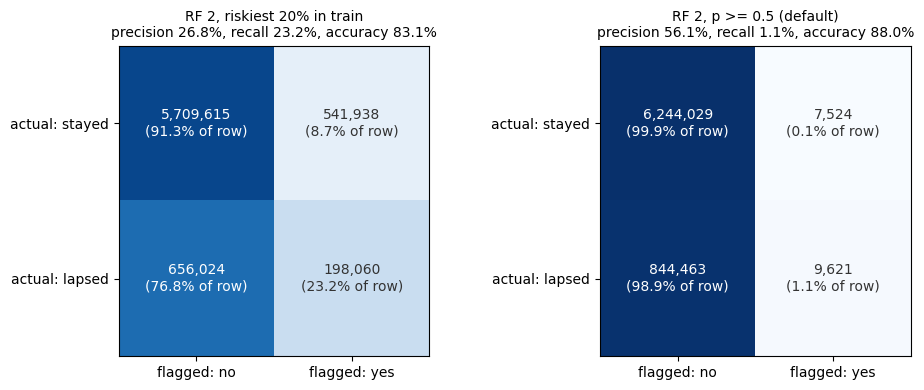

test lapse rate: 12.02%; saying 'nobody lapses' would be 88.0% accurate with 0% recall


,model,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,lift
0,business rule,new and not mortgage-required,,14.8%,"257,145","797,056","596,939","5,454,497",0.804,24.39%,30.1%,0.270,2.03
1,RF 2,p >= 0.5 (default),0.5000,0.2%,"9,621","7,524","844,463","6,244,029",0.880,56.12%,1.1%,0.022,4.67
2,logistic regression,p >= 0.5 (default),0.5000,0.4%,"11,498","16,228","842,586","6,235,325",0.879,41.47%,1.3%,0.026,3.45
3,RF 2,riskiest 10% in train,0.2618,4.2%,"97,098","202,457","756,986","6,049,096",0.865,32.41%,11.4%,0.168,2.70
4,logistic regression,riskiest 10% in train,0.2516,7.3%,"140,893","376,052","713,191","5,875,501",0.847,27.25%,16.5%,0.206,2.27
5,RF 2,riskiest 20% in train,0.2028,10.4%,"198,060","541,938","656,024","5,709,615",0.831,26.76%,23.2%,0.248,2.23
6,logistic regression,riskiest 20% in train,0.1938,14.3%,"245,798","769,524","608,286","5,482,029",0.806,24.21%,28.8%,0.263,2.01
7,RF 2,riskiest 30% in train,0.1674,19.3%,"321,032","1,052,080","533,052","5,199,473",0.777,23.38%,37.6%,0.288,1.95
8,logistic regression,riskiest 30% in train,0.1593,21.5%,"334,827","1,191,538","519,257","5,060,015",0.759,21.94%,39.2%,0.281,1.83


In [48]:
# Step 7.1 Confusion matrices: RF 2 at cut-offs from its out-of-bag training predictions, the default 0.5,
# the simple business rule, and the logistic regression from 06b
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

p_oob = rf2.oob_decision_function_[:, 1]                             # honest training predictions (trees that didn't see the row)
lapse_rate = pred["y"].mean()                                        # the test lapse rate, for the lift

def confusion_row(model, rule, flagged, cut=np.nan):
    '''One row of the results table for a yes/no prediction (flagged = 1 means "will lapse").'''
    tn, fp, fn, tp = confusion_matrix(pred["y"], flagged, labels=[0, 1]).ravel()   # the four boxes
    return {"model": model, "rule": rule, "threshold": cut, "flagged_share": flagged.mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "accuracy": (tp + tn) / len(flagged),                    # share of right predictions
            "precision": precision_score(pred["y"], flagged, zero_division=0),   # of the flagged, share that lapsed
            "recall": recall_score(pred["y"], flagged, zero_division=0),         # of the lapses, share flagged
            "f1": f1_score(pred["y"], flagged, zero_division=0)}               # balance of the two

rows = []
for flag_share in [0.10, 0.20, 0.30, None]:                          # the three rules, then the default
    cut = 0.5 if flag_share is None else float(np.quantile(p_oob, 1 - flag_share))   # e.g. 20% -> the 80th percentile in training
    rule = "p >= 0.5 (default)" if flag_share is None else f"riskiest {flag_share:.0%} in train"   # same names as 06b
    rows.append(confusion_row("RF 2", rule, (pred["p_rf2"] >= cut).astype(int), cut))
rows.append(confusion_row("business rule", "new and not mortgage-required",              # no model: the riskiest segment
                          ((pred["new_business"] == 1) & (pred["mandatory_purchase"] == 0)).astype(int)))
cm_table = pd.DataFrame(rows)

logreg_cm = REPORTS / "lapse_baseline_logreg_test_confusion.csv"     # 06b's confusion results (same test rows)
if logreg_cm.exists():
    cm_table = pd.concat([cm_table, pd.read_csv(logreg_cm).assign(model="logistic regression")], ignore_index=True)
else:
    print(f"(not found: {logreg_cm.name}; pull from GitHub to add the logistic regression)")
cm_table["lift"] = cm_table["precision"] / lapse_rate                # times more lapses than average in the flagged group
cm_table = cm_table[["model", "rule", "threshold", "flagged_share", "TP", "FP", "FN", "TN",
                     "accuracy", "precision", "recall", "f1", "lift"]].sort_values(["rule", "model"]).reset_index(drop=True)

# RF 2 at the middle rule and at the default 0.5, as 2 x 2 tables side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, rule in zip(axes, ["riskiest 20% in train", "p >= 0.5 (default)"]):
    r = cm_table[(cm_table["model"] == "RF 2") & (cm_table["rule"] == rule)].iloc[0]
    m = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])           # rows: actual stayed / lapsed; columns: flagged no / yes
    ax.imshow(m / m.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)   # shade by share of each actual group
    for a in range(2):
        for b in range(2):
            share = m[a, b] / m[a].sum()
            ax.text(b, a, f"{m[a, b]:,}\n({share:.1%} of row)", ha="center", va="center", fontsize=10,
                    color="white" if share > 0.6 else "#333333")
    ax.set_xticks([0, 1], ["flagged: no", "flagged: yes"]); ax.set_yticks([0, 1], ["actual: stayed", "actual: lapsed"])
    ax.set_title(f"RF 2, {rule}\nprecision {r['precision']:.1%}, recall {r['recall']:.1%}, accuracy {r['accuracy']:.1%}", fontsize=10)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_confusion.png", dpi=150)       # saved for the slides and poster
plt.show()
print(f"test lapse rate: {lapse_rate:.2%}; saying 'nobody lapses' would be {1 - lapse_rate:.1%} accurate with 0% recall")
cm_table.style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}",
                       "TN": "{:,}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}",
                       "f1": "{:.3f}", "lift": "{:.2f}"}, na_rep="")

#### 7.2 ROC curve and AUC
Each cut-off gives one confusion matrix. The **ROC curve** shows all of them at once: for every cut-off, the share of lapses caught (recall, or true positive rate) against the share of stayers wrongly flagged (false positive rate):
$$\text{TPR} = \frac{TP}{TP+FN} \qquad \text{FPR} = \frac{FP}{FP+TN}$$
The **AUC** (area under the curve) is the probability that a random lapse gets a higher score than a random stayer: 0.5 = no better than chance, 1.0 = perfect. The dots mark the RF 2 rules of Step 7.1.

AUC measures how well the model **ranks** policy-years, which is what the retention list needs. The table also shows the AUC for each test year, to check that the ranking holds over time.

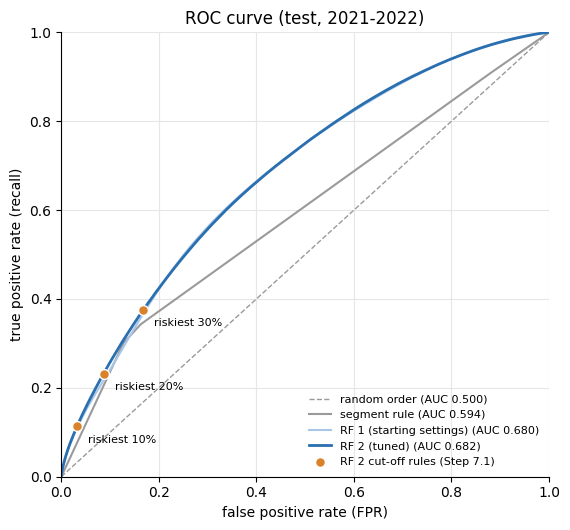

,2021-2022,2021,2022
segment rule,0.594,0.558,0.636
RF 1 (starting settings),0.680,0.701,0.659
RF 2 (tuned),0.682,0.708,0.656


In [49]:
# Step 7.2 ROC curves and AUC (RF 1, RF 2 and the segment rule), overall and per test year
from sklearn.metrics import roc_auc_score, roc_curve

CURVES = {"segment rule": "p_segment", "RF 1 (starting settings)": "p_rf1", "RF 2 (tuned)": "p_rf2"}   # name -> column in pred
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.plot([0, 1], [0, 1], color="#9a9a9a", linewidth=1, linestyle="--", label="random order (AUC 0.500)")
for (name, col), style in zip(CURVES.items(), [dict(color="#9a9a9a", linewidth=1.5),
                                               dict(color="#a9c6e8", linewidth=1.5), dict(color="#2a6fb0", linewidth=2)]):
    fpr, tpr, _ = roc_curve(pred["y"], pred[col])                    # one point per possible cut-off
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(pred['y'], pred[col]):.3f})", **style)
rules = cm_table[(cm_table["model"] == "RF 2") & (cm_table["rule"] != "p >= 0.5 (default)")]   # the three RF 2 rules
ax.scatter(rules["FP"] / (rules["FP"] + rules["TN"]), rules["recall"], color="#d9822b", s=50, zorder=3,
           edgecolor="white", label="RF 2 cut-off rules (Step 7.1)")
for _, r in rules.iterrows():
    ax.annotate(r["rule"].replace(" in train", ""), (r["FP"] / (r["FP"] + r["TN"]), r["recall"]),
                textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.set(title="ROC curve (test, 2021-2022)", xlabel="false positive rate (FPR)", ylabel="true positive rate (recall)",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_roc.png", dpi=150)             # saved for the slides and poster
plt.show()

# AUC overall and for each test year
auc_table = pd.DataFrame({name: {"2021-2022": roc_auc_score(pred["y"], pred[col]),
                                 **{str(y): roc_auc_score(g["y"], g[col]) for y, g in pred.groupby("period_year")}}
                          for name, col in CURVES.items()}).T     # rows: models; columns: periods
auc_table.style.format("{:.3f}")

#### 7.3 Do the results hold in both test years?
The same "riskiest 20%" rule for RF 2, split by year. If precision and recall are similar in 2021 and 2022, the model's performance is stable over time.

In [50]:
# Step 7.3 RF 2's "riskiest 20%" rule in each test year
cut20 = float(np.quantile(p_oob, 0.80))                              # the same cut-off as in Step 7.1
by_year = []
for year, g in pred.groupby("period_year"):                          # 2021, then 2022
    flagged = (g["p_rf2"] >= cut20).astype(int)                      # flagged by the 20% rule
    tn, fp, fn, tp = confusion_matrix(g["y"], flagged, labels=[0, 1]).ravel()
    by_year.append({"year": year, "lapse_rate": g["y"].mean(), "flagged_share": flagged.mean(),
                    "accuracy": (tp + tn) / len(g), "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                    "f1": f1_score(g["y"], flagged, zero_division=0)})
by_year = pd.DataFrame(by_year).set_index("year")
by_year["lift"] = by_year["precision"] / by_year["lapse_rate"]       # lift within each year
by_year.style.format({"lapse_rate": "{:.2%}", "flagged_share": "{:.1%}", "accuracy": "{:.3f}", "precision": "{:.2%}",
                      "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"})

,lapse_rate,flagged_share,accuracy,precision,recall,f1,lift
year,,,,,,,
2021,12.77%,10.4%,0.833,31.00%,25.3%,0.279,2.43
2022,11.23%,10.4%,0.830,22.28%,20.6%,0.214,1.98


#### 7.4 Lapses captured by decile
The test policy-years are sorted by RF 2's probability and cut into 10 equal groups (decile 10 = riskiest). For each decile: its lapse rate, and the share of **all** lapses it holds. The cumulative share is the business version of recall: "if we contact the riskiest 30%, we reach X% of the people who would otherwise leave".

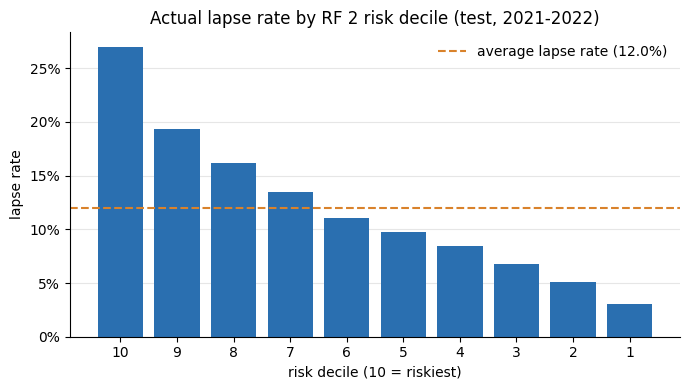

,rows,lapses,actual,predicted,lift,share_of_lapses,cumulative_share
decile,,,,,,,
10,"710,564","191,836",27.00%,27.38%,2.25,22.5%,22.5%
9,"710,564","137,495",19.35%,18.27%,1.61,16.1%,38.6%
8,"710,563","114,891",16.17%,15.32%,1.35,13.5%,52.0%
7,"710,564","95,538",13.45%,13.29%,1.12,11.2%,63.2%
6,"710,563","78,762",11.08%,11.68%,0.92,9.2%,72.4%
5,"710,564","69,501",9.78%,10.24%,0.81,8.1%,80.6%
4,"710,564","59,759",8.41%,8.84%,0.70,7.0%,87.6%
3,"710,563","48,328",6.80%,7.44%,0.57,5.7%,93.2%
2,"710,564","36,379",5.12%,5.92%,0.43,4.3%,97.5%


In [51]:
# Step 7.4 Lapse rate and share of all lapses in each decile of RF 2's probability
pred["decile"] = pd.qcut(pred["p_rf2"].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 equal groups; 10 = riskiest
deciles = (pred.groupby("decile")
               .agg(rows=("y", "size"), lapses=("y", "sum"), actual=("y", "mean"), predicted=("p_rf2", "mean"))
               .sort_index(ascending=False))                         # riskiest decile first
deciles["lift"] = deciles["actual"] / lapse_rate                     # times the average lapse rate
deciles["share_of_lapses"] = deciles["lapses"] / deciles["lapses"].sum()    # share of all test lapses in this decile
deciles["cumulative_share"] = deciles["share_of_lapses"].cumsum()           # top 1, top 2, ... deciles together (= recall)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(deciles.index.astype(str), deciles["actual"], color="#2a6fb0")       # lapse rate per decile
ax.axhline(lapse_rate, color="#d9822b", linestyle="--", linewidth=1.5, label=f"average lapse rate ({lapse_rate:.1%})")
ax.set(title="Actual lapse rate by RF 2 risk decile (test, 2021-2022)", xlabel="risk decile (10 = riskiest)", ylabel="lapse rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_deciles.png", dpi=150)         # saved for the slides and poster
plt.show()
deciles.style.format({"rows": "{:,}", "lapses": "{:,}", "actual": "{:.2%}", "predicted": "{:.2%}", "lift": "{:.2f}",
                      "share_of_lapses": "{:.1%}", "cumulative_share": "{:.1%}"})

#### 7.5 Check: is the missing-ACS leak closed?
Rows whose ACS data was missing lapse far more often (notebook 05, 5.2d), but the team decided the model must not use that. If the random filling works, the forest **can't tell** these rows apart, so:
- its mean prediction for ACS-missing rows should be close to its prediction for the other rows (in the first run, with the median fill: about 23% against 8%);
- ACS-missing rows should make up about the same share of every decile as of all rows (first run: 48% of the top decile, against 11% overall).

The actual lapse rates will still differ a lot between the two groups: that is the information we chose not to use.

In [52]:
# Step 7.5 Check that the forest can no longer pick out the rows with missing ACS data
check = (pred.groupby("acs_missing")
             .agg(rows=("y", "size"), actual=("y", "mean"), predicted=("p_rf2", "mean"))
             .rename(index={False: "ACS present", True: "ACS missing"}))      # lapse rate vs mean prediction, per group
check["share_of_rows"] = check["rows"] / check["rows"].sum()                   # each group's share of the test rows
display(check.style.format({"rows": "{:,}", "actual": "{:.2%}", "predicted": "{:.2%}", "share_of_rows": "{:.1%}"}))

by_decile = pred.groupby("decile")["acs_missing"].mean().sort_index(ascending=False)   # share of ACS-missing rows in each decile
print(f"share of ACS-missing rows: {pred['acs_missing'].mean():.1%} of all test rows; "
      f"{by_decile.loc[10]:.1%} of the top decile (first run with the median fill: 48%)")
by_decile.to_frame("share_acs_missing").T.style.format("{:.1%}")

,rows,actual,predicted,share_of_rows
acs_missing,,,,
ACS present,"6,298,751",8.46%,11.89%,88.6%
ACS missing,"806,886",39.79%,14.64%,11.4%


share of ACS-missing rows: 11.4% of all test rows; 18.6% of the top decile (first run with the median fill: 48%)


decile,10,9,8,7,6,5,4,3,2,1
share_acs_missing,18.6%,17.0%,14.8%,12.8%,11.0%,10.0%,9.1%,7.8%,6.7%,5.7%


#### 7.6 Premium at risk by decile (DRAFT)
This turns the lapse probabilities into money, so managers can see **how much premium is at risk** and what a retention campaign could be worth.

**Expected premium lost** for a policy-year = lapse probability × annual premium. A $1,000 policy with a 27% lapse probability carries $270 of expected lost premium. Summed by decile, this shows where the money at risk is concentrated. We also add up the **actual** premium of the policy-years that really lapsed, to check the forecast.

**Why this is a draft:**
- It uses **RF 2 (uncalibrated)** on the **2021–2022** test years. The final figures for the slides should come from the model the team chooses, scored once on the **2023–2024** holdout in notebook 08. The calculation stays the same; only the probabilities change.
- The campaign numbers use **assumptions** (save rate, cost per contact), set at the top of the cell. Replace them with real figures, or present them as "if … then …".

It uses the test predictions from Section 6; in a fresh session it reads the ones saved in Step 10.1 instead, so it can run on its own after Sections 0.1 and 1.1 (no need to retrain).

Figures are in **US$ per year** (2021–2022 totals divided by 2).

7,105,637 test policy-years; premium missing or negative for 0.00% (counted as $0)


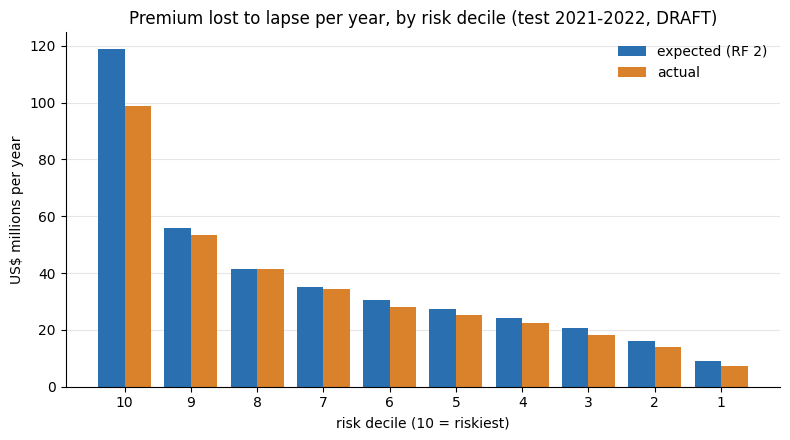

Campaign (illustrative): contact the riskiest 30% = 1,065,846 policies a year; they hold $216M of expected lost premium (56% of all premium actually lost).
If 10% of would-be lapsers are kept: $21.6M premium kept, cost $21.3M at $20 a contact, net $0.3M a year.


,policy_years,premium,predicted_rate,actual_rate,expected_loss,actual_loss,avg_premium,share_of_actual_loss,cumulative_share
decile,,,,,,,,,
10,"355,282","$430,305,500",27.38%,27.00%,"$118,812,710","$98,766,766","$1,211",28.8%,28.8%
9,"355,282","$304,856,962",18.27%,19.35%,"$55,964,261","$53,520,162",$858,15.6%,44.4%
8,"355,282","$270,740,535",15.32%,16.17%,"$41,497,624","$41,431,732",$762,12.1%,56.4%
7,"355,282","$264,309,837",13.29%,13.45%,"$35,146,302","$34,241,562",$744,10.0%,66.4%
6,"355,282","$261,183,982",11.68%,11.08%,"$30,506,413","$27,982,536",$735,8.2%,74.6%
5,"355,282","$267,282,477",10.24%,9.78%,"$27,368,372","$25,303,750",$752,7.4%,81.9%
4,"355,282","$274,793,170",8.84%,8.41%,"$24,293,672","$22,321,098",$773,6.5%,88.4%
3,"355,282","$279,021,146",7.44%,6.80%,"$20,768,729","$18,349,026",$785,5.3%,93.8%
2,"355,282","$272,435,082",5.92%,5.12%,"$16,142,400","$13,903,729",$767,4.1%,97.8%


In [53]:
# Step 7.6 Premium at risk by decile (DRAFT: RF 2 on test 2021-2022; final figures come from the chosen model in notebook 08)
SAVE_RATE = 0.10            # ASSUMPTION: share of contacted would-be lapsers that a retention call keeps (replace when measured)
COST_PER_CONTACT = 20.0     # ASSUMPTION: cost in US$ of one retention contact (replace with a real figure)
TOP_DECILES = 3             # campaign: contact the 3 riskiest deciles (the riskiest 30% of policy-years)
N_YEARS = 2                 # 2021 and 2022: totals are divided by 2 to show "per year"
PRED_FILE = PROCESSED / "predictions" / "lapse_rf_test.parquet"   # the RF test predictions saved in Step 10.1

# The RF 2 test predictions: from memory if Section 6 just ran, otherwise from the file saved in Step 10.1
if "pred" in globals():
    con.register("rf_pred", pred[["period_id", "y", "p_rf2"]])     # let DuckDB read the table in memory
else:
    con.execute(f"CREATE OR REPLACE VIEW rf_pred AS SELECT period_id, y, p_rf2 FROM read_parquet('{PRED_FILE}')")

# Each test policy-year's RF 2 probability, what happened, and its annual premium
money = con.sql('''
    SELECT p.period_id, p.y, p.p_rf2,
           CASE WHEN f.premium > 0 THEN f.premium END AS premium     -- negative premiums are refunds or errors (as in apply_fixed_rules)
    FROM rf_pred p
    JOIN lapse_pop f USING (period_id)
''').df()                                                           # one row per test policy-year
print(f"{len(money):,} test policy-years; premium missing or negative for {money['premium'].isna().mean():.2%} (counted as $0)")
money["premium"] = money["premium"].fillna(0)                       # no usable premium -> no money at risk

money["expected_loss"] = money["p_rf2"] * money["premium"]          # expected lost premium = probability x premium
money["actual_loss"] = money["y"] * money["premium"]                # premium of the policy-years that really lapsed
money["decile"] = pd.qcut(money["p_rf2"].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 = riskiest

par = (money.groupby("decile")
            .agg(policy_years=("y", "size"), premium=("premium", "sum"), predicted_rate=("p_rf2", "mean"),
                 actual_rate=("y", "mean"), expected_loss=("expected_loss", "sum"), actual_loss=("actual_loss", "sum"))
            .sort_index(ascending=False))                           # riskiest decile first
for col in ["policy_years", "premium", "expected_loss", "actual_loss"]:
    par[col] = par[col] / N_YEARS                                   # per year
par["avg_premium"] = par["premium"] / par["policy_years"]           # average premium in the decile
par["share_of_actual_loss"] = par["actual_loss"] / par["actual_loss"].sum()   # share of all premium lost
par["cumulative_share"] = par["share_of_actual_loss"].cumsum()      # top 1, top 2, ... deciles together
par.loc["Total"] = par.sum()                                        # a total row ...
par.loc["Total", ["predicted_rate", "actual_rate"]] = [money["p_rf2"].mean(), money["y"].mean()]   # ... with overall rates
par.loc["Total", "avg_premium"] = par.loc["Total", "premium"] / par.loc["Total", "policy_years"]
par.loc["Total", "cumulative_share"] = np.nan                       # not meaningful for the total

# Chart: expected vs actual premium lost per year, by decile
show = par.drop(index="Total")
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(show))                                            # one position per decile
ax.bar(x - 0.2, show["expected_loss"] / 1e6, width=0.4, color="#2a6fb0", label="expected (RF 2)")
ax.bar(x + 0.2, show["actual_loss"] / 1e6, width=0.4, color="#d9822b", label="actual")
ax.set_xticks(x, [str(d) for d in show.index])
ax.set(title="Premium lost to lapse per year, by risk decile (test 2021-2022, DRAFT)",
       xlabel="risk decile (10 = riskiest)", ylabel="US$ millions per year")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_premium_at_risk_draft.png", dpi=150)   # saved for the slides and poster
plt.show()

# Illustrative campaign: contact the riskiest TOP_DECILES deciles
top = show.head(TOP_DECILES)                                        # the riskiest deciles
contacts = top["policy_years"].sum()                                # policies contacted per year
kept = top["expected_loss"].sum() * SAVE_RATE                       # premium kept per year = premium at risk x save rate
cost = contacts * COST_PER_CONTACT                                  # campaign cost per year
print(f"Campaign (illustrative): contact the riskiest {TOP_DECILES * 10}% = {contacts:,.0f} policies a year; "
      f"they hold ${top['expected_loss'].sum() / 1e6:,.0f}M of expected lost premium "
      f"({top['actual_loss'].sum() / show['actual_loss'].sum():.0%} of all premium actually lost).\n"
      f"If {SAVE_RATE:.0%} of would-be lapsers are kept: ${kept / 1e6:,.1f}M premium kept, "
      f"cost ${cost / 1e6:,.1f}M at ${COST_PER_CONTACT:,.0f} a contact, net ${(kept - cost) / 1e6:,.1f}M a year.")

par.to_csv(REPORTS / "lapse_rf_premium_at_risk_draft.csv")          # saved for notebook 08 and the slides
par.style.format({"policy_years": "{:,.0f}", "premium": "${:,.0f}", "avg_premium": "${:,.0f}",
                  "predicted_rate": "{:.2%}", "actual_rate": "{:.2%}", "expected_loss": "${:,.0f}",
                  "actual_loss": "${:,.0f}", "share_of_actual_loss": "{:.1%}", "cumulative_share": "{:.1%}"}, na_rep="")

### Section 8. What drives the forest
A forest has no coefficients to read, so we measure each feature's importance by **permutation**: shuffle one feature's values across the rows (breaking its link with lapse) and see how much the **ROC-AUC drops**. A big drop = the model relies on that feature to rank policies.

This is done on 50,000 test rows, 3 shuffles per feature, on RF 2. It answers *which* features matter, not in which direction; the EDA (notebook 05), the logistic regression's odds ratios (06b) and SHAP (notebook 09) show the direction.

done in 1.7 min


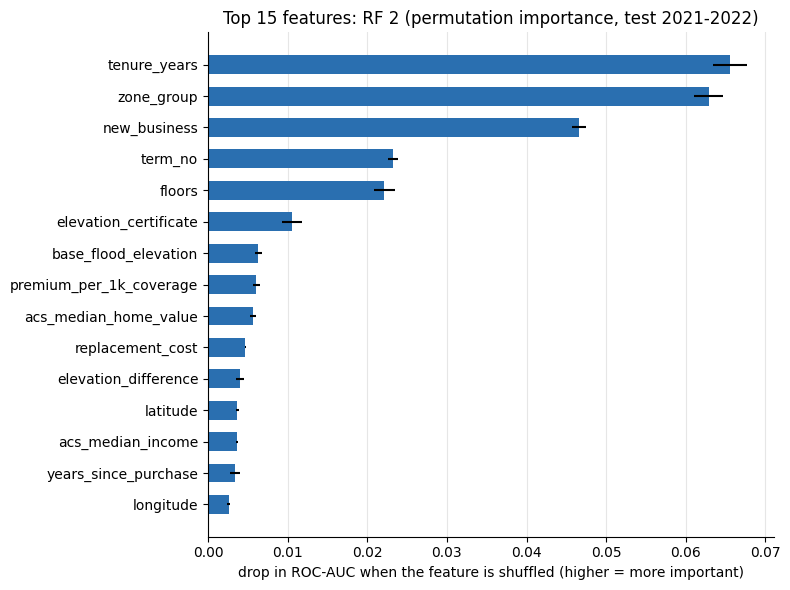

,feature,auc_drop,std,group,kind
0,tenure_years,0.0656,0.0021,tenure,num
1,zone_group,0.0629,0.0018,flood_risk,cat
2,new_business,0.0466,0.0009,tenure,flag
3,term_no,0.0232,0.0006,tenure,num
4,floors,0.0222,0.0013,property,cat
5,elevation_certificate,0.0105,0.0013,flood_risk,cat
6,base_flood_elevation,0.0063,0.0004,flood_risk,num
7,premium_per_1k_coverage,0.0061,0.0004,price,num
8,acs_median_home_value,0.0056,0.0004,context,num
9,replacement_cost,0.0047,0.0001,coverage,num


In [54]:
# Step 8.1 Permutation importance on 50,000 test rows (how much the ROC-AUC drops when a feature is shuffled)
from sklearn.inspection import permutation_importance              # the shuffling method

model_rf2 = make_pipeline(preprocess, rf2)                           # preparation + RF 2 as one object (both already fitted)
X_imp, y_imp, _ = load_rows("test", sample_rows=50_000, seed=SEED + 2)   # a fresh random test sample
t0 = time.time()                                                     # start the stopwatch
imp = permutation_importance(model_rf2, X_imp, y_imp, scoring="roc_auc",        # shuffle each ORIGINAL feature, score by ROC-AUC
                             n_repeats=3, random_state=SEED, n_jobs=1)          # 3 shuffles each, averaged
importance = (pd.DataFrame({"feature": FEATS,
                            "auc_drop": imp.importances_mean,                   # average drop in ROC-AUC
                            "std": imp.importances_std})                        # how much it varies between shuffles
                .merge(plan[["feature", "group", "kind"]], on="feature")       # add the feature group (price, tenure, ...)
                .sort_values("auc_drop", ascending=False).reset_index(drop=True))
print(f"done in {(time.time() - t0) / 60:.1f} min")

top = importance.head(15)                                            # the 15 most important features
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"][::-1], top["auc_drop"][::-1], xerr=top["std"][::-1], color="#2a6fb0", height=0.6)
ax.set(title="Top 15 features: RF 2 (permutation importance, test 2021-2022)",
       xlabel="drop in ROC-AUC when the feature is shuffled (higher = more important)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_importance.png", dpi=150)       # saved for the slides and poster
plt.show()
importance.head(20).style.format({"auc_drop": "{:.4f}", "std": "{:.4f}"})

### Section 9. Ad hoc: probability measures
The forest's output is a **probability**, and some uses need the probability *values* to be right, not just the ranking: expected lapses next year, and premium at risk (Step 7.6). These measures check that. They are kept here for reference; the main results are in Section 7.

| Measure | What it checks | Better |
|---|---|---|
| **Log loss** | Average penalty per policy-year: small when the model gave a high probability to what happened, large when it was confidently wrong | lower |
| **Brier score** | Average squared gap between the probability and what happened (1 = lapsed, 0 = stayed); gentler on confident mistakes | lower |
| **Skill** | Improvement over giving everyone the training lapse rate (0% = no better) | higher |
| **Calibration** | Within groups of policies, does a predicted 20% really mean about 20% lapse? | close to the diagonal |

#### 9.1 Log loss and Brier score
Same scores as 06b, for the two benchmarks, RF 1 and RF 2. The logistic regression's results are read from `reports/lapse_baseline_logreg_test_metrics.csv` (saved by 06b), on the same 7.1M test rows.

In [55]:
# Step 9.1 Log loss and Brier: the forests against the benchmarks (and the logistic regression from 06b)
MODELS = {"base rate": "p_base", "segment rate": "p_segment",       # model name -> its column in pred
          "RF 1 (starting settings)": "p_rf1", "RF 2 (tuned)": "p_rf2"}

def scores(y, p):
    '''The scores for one set of rows: counts, rates, log loss and Brier.'''
    return {"rows": len(y), "lapses": int(y.sum()), "actual_rate": y.mean(), "predicted_rate": p.mean(),
            "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p)}

rows = []                                                            # one row per period x model
for scope, part in [("2021-2022", pred), *[(str(y), g) for y, g in pred.groupby("period_year")]]:   # both years together, then each year
    for name, col in MODELS.items():                                 # every model
        rows.append({"scope": scope, "model": name, **scores(part["y"], part[col])})
results = pd.DataFrame(rows)

logreg_file = REPORTS / "lapse_baseline_logreg_test_metrics.csv"     # 06b's saved results
if logreg_file.exists():                                             # if a teammate has shared it ...
    lr = pd.read_csv(logreg_file)
    lr = lr[lr["model"] == "logistic regression"]                    # ... add the logistic regression rows
    results = pd.concat([results, lr[[c for c in results.columns if c in lr.columns]]], ignore_index=True)
    results["scope"] = results["scope"].astype(str)
else:
    print(f"(not found: {logreg_file.name}; ask Sebastian to push it, then re-run this cell)")

base = results[results["model"] == "base rate"].set_index("scope")  # the base rate's scores, per period
results["log_loss_skill"] = 1 - results["log_loss"] / results["scope"].map(base["log_loss"])   # improvement in log loss over the base rate
results["brier_skill"] = 1 - results["brier"] / results["scope"].map(base["brier"])            # improvement in Brier over the base rate
results = results.sort_values(["scope", "log_loss"]).reset_index(drop=True)   # best model first within each period
results.style.format({"rows": "{:,}", "lapses": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                      "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}", "brier_skill": "{:+.2%}"})

,scope,model,rows,lapses,actual_rate,predicted_rate,log_loss,brier,log_loss_skill,brier_skill
0,2021,RF 2 (tuned),"3,648,441","465,877",12.769%,11.708%,0.35202,0.104359,+7.96%,+6.41%
1,2021,RF 1 (starting settings),"3,648,441","465,877",12.769%,11.450%,0.35570,0.105289,+7.00%,+5.57%
2,2021,logistic regression,"3,648,441","465,877",12.769%,11.664%,0.36508,0.107338,+4.55%,+3.73%
3,2021,segment rate,"3,648,441","465,877",12.769%,13.102%,0.37728,0.110135,+1.36%,+1.23%
4,2021,base rate,"3,648,441","465,877",12.769%,13.839%,0.38247,0.111501,+0.00%,+0.00%
5,2021-2022,RF 2 (tuned),"7,105,637","854,084",12.020%,12.206%,0.34460,0.100612,+6.55%,+5.16%
6,2021-2022,RF 1 (starting settings),"7,105,637","854,084",12.020%,11.628%,0.34620,0.101011,+6.12%,+4.78%
7,2021-2022,logistic regression,"7,105,637","854,084",12.020%,11.857%,0.35129,0.102191,+4.74%,+3.67%
8,2021-2022,segment rate,"7,105,637","854,084",12.020%,13.394%,0.35819,0.103381,+2.87%,+2.55%
9,2021-2022,base rate,"7,105,637","854,084",12.020%,13.839%,0.36876,0.106082,+0.00%,+0.00%


#### 9.2 Calibration
Predicted vs actual lapse rate in each decile of Step 7.4 (points on the diagonal = the probabilities can be used as they are), and the **expected number of lapses** (the sum of the probabilities) against the actual number, per test year.

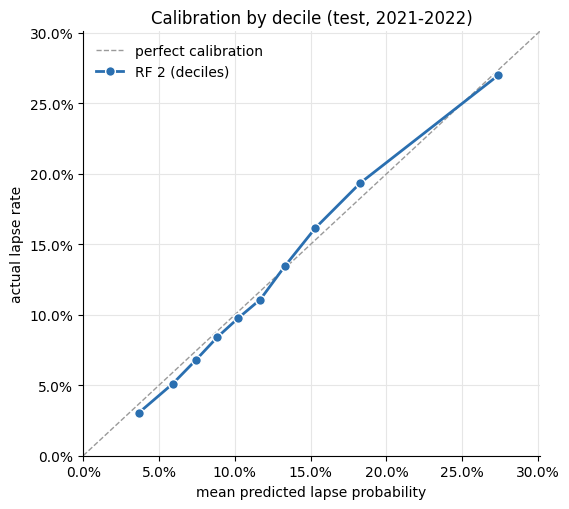

,actual,expected_base rate,expected_segment rate,expected_RF 1 (starting settings),expected_RF 2 (tuned)
period_year,,,,,
2021,"465,877","504,917","478,033","417,758","427,146"
2022,"388,207","478,451","473,704","408,461","440,135"
2021-2022,"854,084","983,368","951,737","826,219","867,281"


In [56]:
# Step 9.2 Calibration by decile (RF 2) and expected vs actual lapses
from matplotlib.ticker import PercentFormatter                       # shows axis numbers as percentages

fig, ax = plt.subplots(figsize=(5.8, 5.2))
lim = max(deciles["predicted"].max(), deciles["actual"].max()) * 1.1   # axis limit
ax.plot([0, lim], [0, lim], color="#9a9a9a", linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(deciles["predicted"], deciles["actual"], color="#2a6fb0", linewidth=2, marker="o", markersize=7,
        markeredgecolor="white", label="RF 2 (deciles)")
ax.set(title="Calibration by decile (test, 2021-2022)", xlabel="mean predicted lapse probability",
       ylabel="actual lapse rate", xlim=(0, lim), ylim=(0, lim))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_calibration.png", dpi=150)
plt.show()

expected = (pred.groupby("period_year")                              # expected (sum of probabilities) vs actual lapses
                .agg(actual=("y", "sum"), **{f"expected_{n}": (c, "sum") for n, c in MODELS.items()}))
expected.loc["2021-2022"] = expected.sum()                          # both years together
expected.style.format("{:,.0f}")

#### 9.3 Does a calibration step help?
Random-forest probabilities are often **squeezed towards the middle**: an average of many trees rarely says 1% or 60%, even when the truth is that extreme. A **calibration** step learns a correction curve: "when the forest says 8%, the real lapse rate is 5%".

**Isotonic calibration** fits a curve that only goes up (a higher forest score never gets a lower probability), so the order of the policies doesn't change; only the probability values do.

**What we fit it on:** the **out-of-bag** predictions of RF 2 (Section 4). Each training row is scored only by the trees that never saw it, so the curve is learned on honest predictions, not on the rows the trees memorised. The test years are still untouched.

We then apply it to the test years and compare RF 2 with and without it. (In our run it made the results slightly *worse*, so the model carried forward is RF 2 **without** calibration.)

calibration learned on 1,000,000 out-of-bag predictions (0 rows without one)


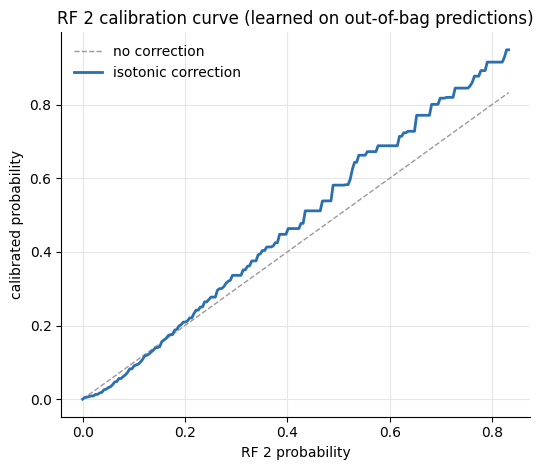

,model,log_loss,brier,predicted_rate,actual_rate
0,RF 2 (tuned),0.34460,0.100612,12.206%,12.020%
1,RF 2 + calibration,0.34553,0.100806,11.594%,12.020%


In [57]:
# Step 9.3 Isotonic calibration of RF 2, learned on its out-of-bag (honest) training predictions
p_oob = rf2.oob_decision_function_[:, 1]                             # each training row's lapse probability from the trees that didn't see it
ok = np.isfinite(p_oob)                                              # (a row seen by every tree would have no OOB prediction; normally none)
calibrator = IsotonicRegression(out_of_bounds="clip",                # scores outside the training range get the nearest end of the curve
                                y_min=1e-4, y_max=1 - 1e-4)          # never exactly 0% or 100% (log loss would be infinite)
calibrator.fit(p_oob[ok], y_train.to_numpy()[ok])                    # learn: forest score -> real lapse rate
print(f"calibration learned on {ok.sum():,} out-of-bag predictions ({(~ok).sum()} rows without one)")

def calibrated(p):
    '''Apply the calibration curve to RF 2 probabilities.'''
    return calibrator.predict(p)                                     # look up each score on the curve

# The curve as a picture: forest score (x) -> calibrated probability (y)
grid = np.linspace(0, np.quantile(p_oob[ok], 0.999), 200)            # forest scores from 0 to almost the highest
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.plot([0, grid.max()], [0, grid.max()], color="#9a9a9a", linestyle="--", linewidth=1, label="no correction")
ax.plot(grid, calibrated(grid), color="#2a6fb0", linewidth=2, label="isotonic correction")
ax.set(title="RF 2 calibration curve (learned on out-of-bag predictions)",
       xlabel="RF 2 probability", ylabel="calibrated probability")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6")
plt.tight_layout(); plt.show()

# Apply it to the test years and compare with RF 2 as it is
pred["p_rf2_cal"] = calibrated(pred["p_rf2"].to_numpy())            # calibrated RF 2 probability for every test row
compare = pd.DataFrame([{"model": name, "log_loss": log_loss(pred["y"], pred[col]), "brier": brier_score_loss(pred["y"], pred[col]),
                         "predicted_rate": pred[col].mean(), "actual_rate": lapse_rate}
                        for name, col in [("RF 2 (tuned)", "p_rf2"), ("RF 2 + calibration", "p_rf2_cal")]])
compare.style.format({"log_loss": "{:.5f}", "brier": "{:.6f}", "predicted_rate": "{:.3%}", "actual_rate": "{:.3%}"})

### Section 10. Save
#### 10.1 Save the model and results
Same places and naming as 06b: the model in `data/processed/models/`, the test predictions in `data/processed/predictions/` (both stay off GitHub), and the tables, figures and run record in `reports/` (pushed to GitHub).

To use the saved model elsewhere (RF 2, without calibration): `p = model.predict_proba(preprocess.transform(X).astype("float32"))[:, 1]`. The calibration curve is stored too (`calibrator`) but not used.

In [58]:
# Step 10.1 Save the model, the test predictions and the results
import json                                                          # writes the run record
import joblib                                                        # saves Python objects (the model) to a file
from datetime import datetime                                        # the time stamp

MODEL_DIR = PROCESSED / "models"                                     # models folder (not on GitHub)
PRED_DIR = PROCESSED / "predictions"                                 # predictions folder (not on GitHub)
for d in (MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)                             # create them if needed
NAME = "lapse_rf"                                                    # file name prefix for this model

# The model: preparation + RF 2 + calibration curve, in one file
joblib.dump({"preprocess": preprocess, "model": rf2, "calibrator": calibrator, "features": FEATS},
            MODEL_DIR / f"{NAME}.joblib", compress=3)                # compress: forests are large files

# Test predictions, row by row, so notebook 08 can compare models without retraining
pred[["period_id", "period_year", "y", "p_rf1", "p_rf2", "p_rf2_cal", "p_segment", "p_base"]].to_parquet(
    PRED_DIR / f"{NAME}_test.parquet", index=False)

# Results tables for GitHub
results.to_csv(REPORTS / f"{NAME}_test_metrics.csv", index=False)
cm_table.to_csv(REPORTS / f"{NAME}_test_confusion.csv", index=False)
auc_table.to_csv(REPORTS / f"{NAME}_test_auc.csv")
deciles.to_csv(REPORTS / f"{NAME}_test_deciles.csv")
tuning.to_csv(REPORTS / f"{NAME}_tuning.csv", index=False)
importance.to_csv(REPORTS / f"{NAME}_permutation_importance.csv", index=False)

# Run record: what was trained, on what, with which settings
run = {
    "model": NAME, "target": TARGET, "saved_at": datetime.now().isoformat(timespec="seconds"),
    "train_split": f"train (2014-2020), random sample of {TRAIN_ROWS:,} rows (seed {SEED})",
    "tuning": f"rolling-origin folds 2017-2020 on {TUNE_ROWS:,} rows; best min_samples_leaf={BEST_LEAF}, max_features={BEST_MAXF}",
    "calibration": "isotonic, fitted on RF 2 out-of-bag predictions; not used (made test results slightly worse)",
    "cutoffs": "riskiest 10/20/30% of RF 2 out-of-bag training predictions",
    "random_filled_features": num_random,                            # filled with random training values (run 2)
    "scored_on": "test (2021-2022), every row",
    "features_used": FEATS, "model_columns": int(len(COLS)),
    "params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in rf2.get_params().items()},
    "seed": SEED, "base_rate_train": base_rate,
    "test_overall": results.query("scope == '2021-2022' and model == 'RF 2 (tuned)'").iloc[0].drop(["scope", "model"]).to_dict(),
    "test_auc": float(auc_table.loc["RF 2 (tuned)", "2021-2022"]),
    "test_confusion_20pct": cm_table.query("model == 'RF 2' and rule == 'riskiest 20% in train'").iloc[0].drop(["model", "rule"]).to_dict(),
}
(REPORTS / f"{NAME}_run.json").write_text(json.dumps(run, indent=2, default=float))

# Check: the saved model loads and gives the same predictions
saved = joblib.load(MODEL_DIR / f"{NAME}.joblib")                    # read it back
X_check, _, _ = load_rows("test", sample_rows=1000)                  # 1,000 test rows
p_saved = saved["model"].predict_proba(saved["preprocess"].transform(X_check).astype(np.float32))[:, 1]
p_now = rf2.predict_proba(preprocess.transform(X_check).astype(np.float32))[:, 1]
print(f"saved {NAME}.joblib ({(MODEL_DIR / f'{NAME}.joblib').stat().st_size / 1e6:.0f} MB), test predictions, "
      f"confusion matrices, AUC, metrics, deciles, tuning, importance and run record; reload gives the same predictions: {np.allclose(p_saved, p_now)}")

saved lapse_rf.joblib (111 MB), test predictions, confusion matrices, AUC, metrics, deciles, tuning, importance and run record; reload gives the same predictions: True


### Findings

- **Ranking (ROC-AUC, Step 7.2):** RF 2 = **0.682** (2021: 0.708, 2022: 0.656), vs 0.594 for the segment rule. RF 1 (starting settings) is almost the same (0.680): tuning adds little.
- **Accuracy is misleading (Step 7.1):** at the default p ≥ 0.5, RF 2 flags 0.2% of policy-years and is 88.0% accurate, but catches only 1.1% of lapses: the same accuracy as predicting that nobody lapses.
- **Cut-off rules (Step 7.1):** cut-offs set on the training years flag fewer policy-years in 2021–2022 (4.2% / 10.4% / 19.3% for the 10/20/30% rules), because test policies score lower. At the "riskiest 20%" rule: precision 26.8%, recall 23.2%, F1 0.248, lift 2.23.
- **Against logistic regression (06b):** compared at similar list sizes, the two perform about the same (RF flags 19.3% → recall 37.6%, precision 23.4%; logistic flags 21.5% → recall 39.2%, precision 21.9%). RF's AUC is somewhat higher than the logistic regression's (to be confirmed once 06b's AUC is saved).
- **Against a simple business rule** (contact every new, non-mortgage policyholder): precision 24.4%, recall 30.1%, F1 0.270, lying about on the RF curve at that list size. The forest's advantage is that it ranks every policy, so the retention team can choose any list size.
- **Stability (Step 7.3):** the model is weaker in 2022 (20% rule: precision 31.0% → 22.3%, recall 25.3% → 20.6%; AUC 0.708 → 0.656), when the simple segment rule nearly catches up (AUC 0.636).
- **Lapses captured (Step 7.4):** the riskiest 10% lapse at 27.0% (2.25× the average 12.0%) and hold 22.5% of lapses; the riskiest 30% hold 52.0%. Predicted and actual lapse rates match closely in every decile.
- **Leak check (Step 7.5):** ACS-missing rows are 18.6% of the top decile vs 11.4% of all rows (48% with the median fill in the first run): the random-draw fill closed the back door.
- **Premium at risk (Step 7.6, draft):** about $343M of premium is lost to lapse per year in 2021–2022; the riskiest 30% hold 56% of it. Under illustrative assumptions (10% save rate, $20 per contact), contacting the riskiest 10% nets about +$3–5M a year, while contacting 30% only breaks even, so a smaller, sharper list is better.
- **Main drivers (Section 8, drop in ROC-AUC when shuffled):**
  1. **Tenure** – `tenure_years` (0.066), `new_business` (0.047), `term_no` (0.023): new policyholders leave most.
  2. **Flood zone** – `zone_group` (0.063), nearly tied with tenure; lower-risk zones (X) lapse more (direction from the EDA and 06b's odds ratios).
  3. **Property type** – `floors` (0.022).
  4. **Flood-risk documentation** – `elevation_certificate` (0.011), `base_flood_elevation` (0.006).
  - Price per $1,000 of cover (0.006) and tract home value (0.006) are minor; mandatory purchase, premium changes and recent disasters are not in the top 20 (mandatory purchase likely overlaps with flood zone). The same top 5 appeared when importance was measured by log loss, so the ranking is robust.
- **Ad hoc (Section 9):** log loss 0.3446, 6.6% better than the base rate (logistic regression 4.7%); expected 867K vs 854K actual lapses (+1.5%). Isotonic calibration made results slightly worse, so RF 2 is used without it.
- **Model carried to notebook 08:** RF 2 (tuned), uncalibrated (`p_rf2`).